# Quantinuum color-code memory with LightStim

A **d=3 circuit reconstruction** of [Lavasani et al., arXiv:2610.24077v1](https://arxiv.org/abs/2610.24077v1): Bell-flag preparation, SWAP-superdense memory, and destructive readout. The paper averages six signed logical Pauli inputs over 20 memory rounds. Flags are decoded, not postselected.

**Scope:** the noise below is a specified Pauli model, not Quantinuum's calibrated Helios emulator. The current reconstruction has a documented Y-readout weight-two fault witness; it does not establish full distance-three protection in all bases. See [README](README.md) for checks and limitations.

In [1]:
import json
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lightstim').is_dir())
sys.path.insert(0, str(ROOT))
HERE = ROOT / 'examples/quantinuum_color_code_memory'

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from examples.quantinuum_color_code_memory.circuit import build_circuit, noise_config
from examples.quantinuum_color_code_memory.run import run_case
from examples.quantinuum_color_code_memory.plot import plot_comparison

## Circuit and detector slices

For a readable diagram, show preparation, all three cyclic memory schedules, and readout for logical +Z. Every tick is included. The statistical comparison below uses the full 20-round experiment. `SWAP[noiseless]` denotes software wire relabeling, not a physical noisy SWAP.

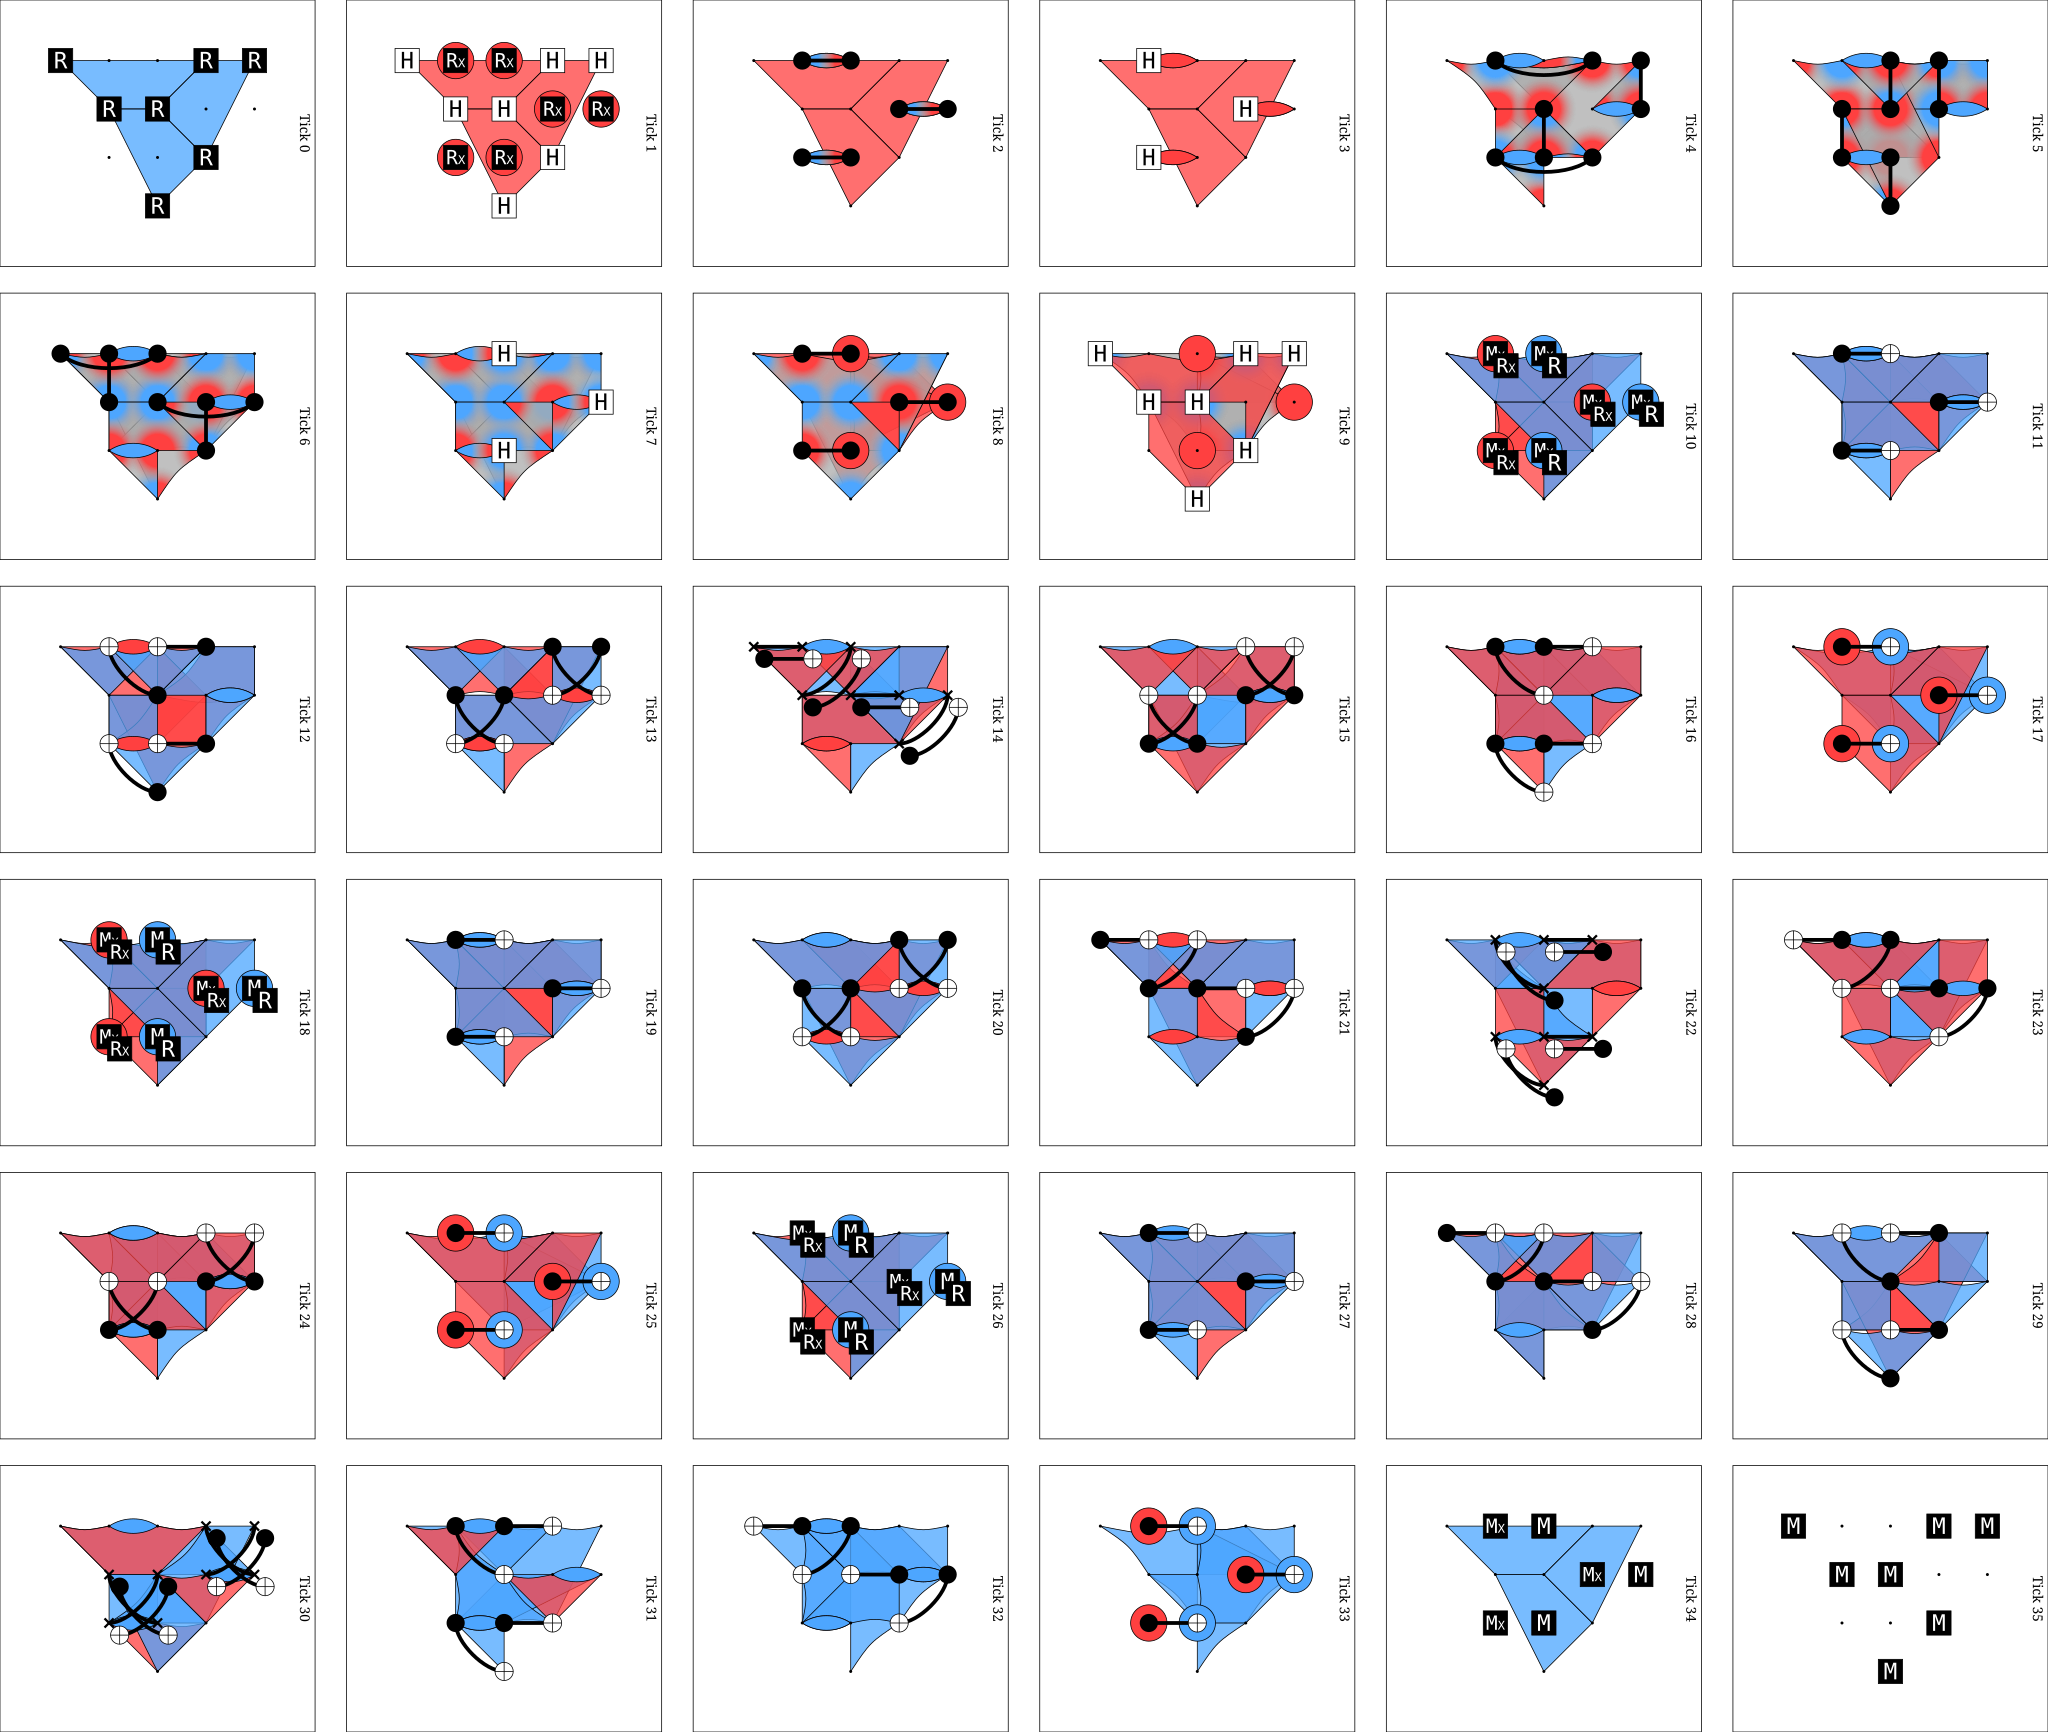

In [2]:
circuit = build_circuit(rounds=3, basis='Z')
display(SVG(str(circuit.diagram('detslice-with-ops-svg', tick=range(circuit.num_ticks + 1)))))

## Small pipeline run

This uses the standard `SimulationPipeline` with Tesseract and physical-circuit sampling. The low shot count is only a runnable usage example; it is not enough to estimate a small LER precisely. To include moment-based idling, select `circuit_level_with_idling`; the reference study evaluates both models with fixed rates.

In [3]:
model = 'circuit_level'
display(noise_config(model))
small_run = run_case(basis='Z', rounds=20, shots=256, noise_model=model)
display(pd.DataFrame([{key: small_run[key] for key in
                      ('basis', 'sign', 'rounds', 'shots', 'accepted', 'errors', 'normalized_rate')}]))

NoiseConfig(p_1q=0.001, p_2q=0.001, p_meas=0.001, p_reset=0.001, p_idle=0, custom_params={})

,basis,sign,rounds,shots,accepted,errors,normalized_rate
0,Z,1,20,256,256,3,0.000572


## Stored 20-round comparison

50,000 shots per signed Pauli state per model. Gate, reset and measurement rates are 0.001; idle noise is 0 for `circuit_level` and 0.001 per inactive qubit per moment for `circuit_level_with_idling`. These are not fitted to the hardware point.

The plotted estimator is `failures / shots / 20.5`, averaged over all six inputs, including Y. All intervals are 95%; simulation bounds are conservative simultaneous exact bounds. The paper's hardware point is 178/15,840, approximately 5.5e-4 per round.

,noise_model,basis,sign,shots,errors,normalized_rate
0,circuit_level,X,1,50000,170,0.000166
1,circuit_level,X,-1,50000,198,0.000193
2,circuit_level,Y,1,50000,315,0.000307
3,circuit_level,Y,-1,50000,323,0.000315
4,circuit_level,Z,1,50000,182,0.000178
5,circuit_level,Z,-1,50000,187,0.000182
6,circuit_level_with_idling,X,1,50000,1298,0.001266
7,circuit_level_with_idling,X,-1,50000,1276,0.001245
8,circuit_level_with_idling,Y,1,50000,1726,0.001684
9,circuit_level_with_idling,Y,-1,50000,1739,0.001697


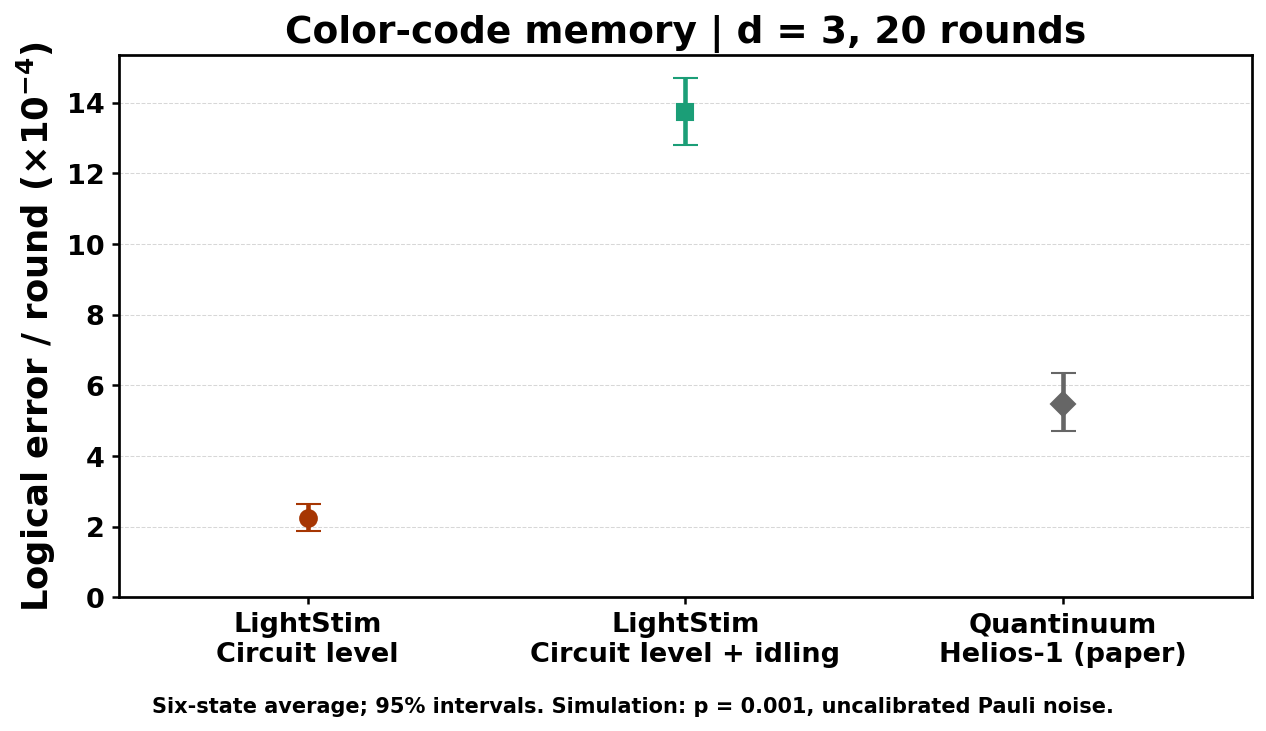

In [4]:
report = json.loads((HERE / 'results.json').read_text())
display(pd.DataFrame(report['cases'])[['noise_model', 'basis', 'sign', 'shots', 'errors', 'normalized_rate']])
figure = plot_comparison(report)
plt.show()